# Lab 05 — Inside a pretrained language model

**Book sections:** [1.1 Language models in operation](../../book/docs/chapters/01-multimodal-intro/language.md),
[2.2](../../book/docs/chapters/02-transformers/multi-head.md)–[2.7](../../book/docs/chapters/02-transformers/scaling.md).

**Goal.** Open a real modern LLM — SmolLM2-135M, a Llama-architecture model (RMSNorm, SwiGLU, RoPE,
grouped-query attention, tied embeddings) — and check everything Chapter 2 claims: its parameter count
from the configuration, the shapes of hidden states and attention maps, next-token distributions,
decoding strategies implemented by hand with a KV cache, attention-head patterns, the logit lens, and
prefill/decode timing against the memory-bandwidth bound.

**Runtime:** ≈1 minute. **Downloads:** ≈270 MB (model weights, cached in `data/hf`). **GPU:** optional
(< 1 GB VRAM). **Seed:** 0.

In [1]:
import os
import time
from pathlib import Path

os.environ.setdefault("HF_HOME", str(Path("../../data/hf").resolve()))

import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

from vlacourse.data.instructions import RUNNING_EXAMPLE
from vlacourse.seed import device, set_seed

set_seed(0)
dev = device()
NAME = "HuggingFaceTB/SmolLM2-135M"
tok = AutoTokenizer.from_pretrained(NAME)
# "eager" attention returns attention weights; fused kernels (SDPA/FlashAttention) do not materialise them.
model = AutoModelForCausalLM.from_pretrained(NAME, dtype=torch.float32, attn_implementation="eager").to(dev).eval()
cfg = model.config
print(model)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 576)
    (layers): ModuleList(
      (0-29): 30 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=576, out_features=576, bias=False)
          (k_proj): Linear(in_features=576, out_features=192, bias=False)
          (v_proj): Linear(in_features=576, out_features=192, bias=False)
          (o_proj): Linear(in_features=576, out_features=576, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=576, out_features=1536, bias=False)
          (up_proj): Linear(in_features=576, out_features=1536, bias=False)
          (down_proj): Linear(in_features=1536, out_features=576, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((576,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((576,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((576,), eps=1e-05)
    (rotary_emb): Lla

## 1. Configuration and parameter count
Book 2.7: per block, attention $= 2d^2 + 2\,d\,h_{kv}d_h$ (Q and O are $d\times d$; K and V are
$d\times h_{kv}d_h$ with GQA), SwiGLU $=3\,d\,d_\text{ff}$, two RMSNorm vectors; plus the tied embedding
$Vd$ and a final norm.

In [2]:
d, L, h, h_kv, d_ff, V = (cfg.hidden_size, cfg.num_hidden_layers, cfg.num_attention_heads,
                          cfg.num_key_value_heads, cfg.intermediate_size, cfg.vocab_size)
d_h = d // h
per_block = 2 * d * d + 2 * d * h_kv * d_h + 3 * d * d_ff + 2 * d
formula = L * per_block + V * d + d
actual = sum(p.numel() for p in model.parameters())
print(f"d={d} L={L} h={h} h_kv={h_kv} d_h={d_h} d_ff={d_ff} V={V} tied={cfg.tie_word_embeddings}")
print(f"formula {formula:,}   actual {actual:,}")
assert formula == actual
print(f"embedding share: {V * d / actual:.1%};  blocks: attention {L * (2*d*d + 2*d*h_kv*d_h) / actual:.1%}, "
      f"FFN {L * 3 * d * d_ff / actual:.1%}")

d=576 L=30 h=9 h_kv=3 d_h=64 d_ff=1536 V=49152 tied=True
formula 134,515,008   actual 134,515,008
embedding share: 21.0%;  blocks: attention 19.7%, FFN 59.2%


## 2. One forward pass, all the tensors

In [3]:
enc = tok(RUNNING_EXAMPLE, return_tensors="pt").to(dev)
tokens = [tok.decode([i]) for i in enc.input_ids[0]]
with torch.no_grad():
    out = model(**enc, output_hidden_states=True, output_attentions=True)
print("input_ids        ", tuple(enc.input_ids.shape), "(B, T)")
print("logits           ", tuple(out.logits.shape), "(B, T, V)")
print("hidden_states    ", len(out.hidden_states), "x", tuple(out.hidden_states[0].shape), "(embeddings + one per layer)")
print("attentions       ", len(out.attentions), "x", tuple(out.attentions[0].shape), "(B, h, T, T) per layer")
print("rows sum to 1:", torch.allclose(out.attentions[5].sum(-1), torch.ones(1, h, len(tokens), device=dev), atol=1e-4))
print("causal (no weight above the diagonal):", out.attentions[5][0].triu(1).abs().max().item())

input_ids         (1, 19) (B, T)
logits            (1, 19, 49152) (B, T, V)
hidden_states     31 x (1, 19, 576) (embeddings + one per layer)
attentions        30 x (1, 9, 19, 19) (B, h, T, T) per layer
rows sum to 1: True
causal (no weight above the diagonal): 0.0


## 3. What does the model expect next?

In [4]:
def top_next(prefix, k=8):
    ids = tok(prefix, return_tensors="pt").input_ids.to(dev)
    with torch.no_grad():
        p = model(ids).logits[0, -1].float().softmax(-1)      # last row only: the next token
    top = p.topk(k)
    return [(tok.decode([i]), round(v.item(), 3)) for v, i in zip(top.values, top.indices)]


for prefix in ["Survey the east yard, find the red toolbox, and bring it to the",
               "Survey the east yard, find the red toolbox, and bring it to the inspection",
               "The drone must not fly over the"]:
    print(f"{prefix!r}\n   -> {top_next(prefix)}")

'Survey the east yard, find the red toolbox, and bring it to the'
   -> [(' front', 0.077), (' window', 0.019), ('\n', 0.019), (' door', 0.017), (' table', 0.017), (' lab', 0.014), (' center', 0.014), (' office', 0.014)]
'Survey the east yard, find the red toolbox, and bring it to the inspection'
   -> [(' table', 0.129), (' room', 0.113), (' area', 0.087), ('.', 0.084), (' desk', 0.066), (' station', 0.048), (' hall', 0.041), (' office', 0.019)]
'The drone must not fly over the'
   -> [(' area', 0.019), (' same', 0.018), (' ground', 0.016), ('\n', 0.013), (' city', 0.013), (' site', 0.01), (' water', 0.009), (' land', 0.008)]


## 4. Decoding by hand, with a KV cache
The loop of book 1.1: prefill once, then feed only the newest token while the model keeps its cache.

In [5]:
def sample_next(logits, temperature=1.0, top_p=1.0, generator=None):
    if temperature == 0:
        return int(logits.argmax())
    probs = (logits / temperature).softmax(-1)
    sorted_p, idx = probs.sort(descending=True)
    keep = sorted_p.cumsum(-1) - sorted_p < top_p
    sorted_p = sorted_p * keep
    return int(idx[torch.multinomial(sorted_p / sorted_p.sum(), 1, generator=generator)])


@torch.no_grad()
def generate(prompt, n_new=20, temperature=0.0, top_p=1.0, seed=0):
    g = torch.Generator(device=dev).manual_seed(seed)
    ids = tok(prompt, return_tensors="pt").input_ids.to(dev)
    out = model(ids, use_cache=True)                         # prefill
    past, new = out.past_key_values, []
    for _ in range(n_new):
        nxt = sample_next(out.logits[0, -1], temperature, top_p, g)
        new.append(nxt)
        out = model(torch.tensor([[nxt]], device=dev), past_key_values=past, use_cache=True)   # decode
        past = out.past_key_values
    return tok.decode(new)


prompt = "Robot instructions:\n1. Survey the east yard.\n2."
print("greedy      :", repr(generate(prompt)))
print("T=0.7       :", repr(generate(prompt, temperature=0.7)))
print("T=1.5       :", repr(generate(prompt, temperature=1.5)))
print("T=1, top-p .9:", repr(generate(prompt, temperature=1.0, top_p=0.9)))

# Our greedy loop must match the library's.
ref = model.generate(**tok(prompt, return_tensors="pt").to(dev), max_new_tokens=20, do_sample=False)
assert tok.decode(ref[0, -20:]) == generate(prompt)
print("hand-written greedy == model.generate: True")

greedy      : ' Survey the west yard.\n3. Survey the north yard.\n4. Survey the south yard'


T=0.7       : ' Walk to the east yard and put your cursor on the door.\n3. Walk around to the'


T=1.5       : ' Overhead throttles disposable greenhouse thickness limits resemble hypothesis Finnish dream rider\nH utkering told'


T=1, top-p .9: ' Change the LUG to 10D rating.\n3. Turn left and drive 6'


hand-written greedy == model.generate: True


## 5. Attention heads
Score every head by how much weight it puts on the *previous* token and on the *first* token
(the "attention sink").

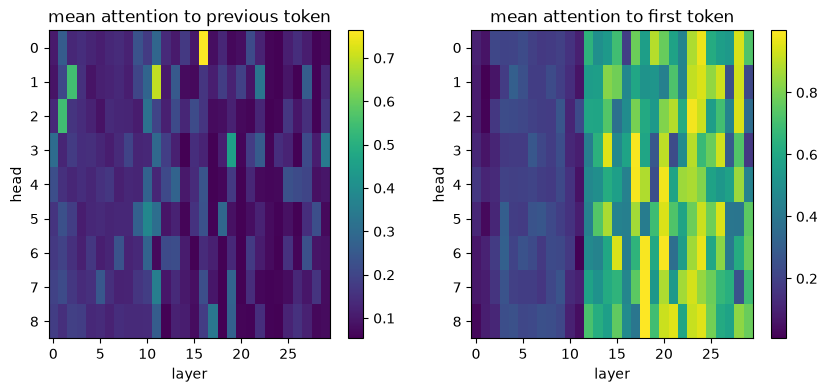

strongest previous-token head: layer 16, head 0 (0.76)
mean attention to the first token, layers 0-2: 0.10; layers 10-29: 0.61


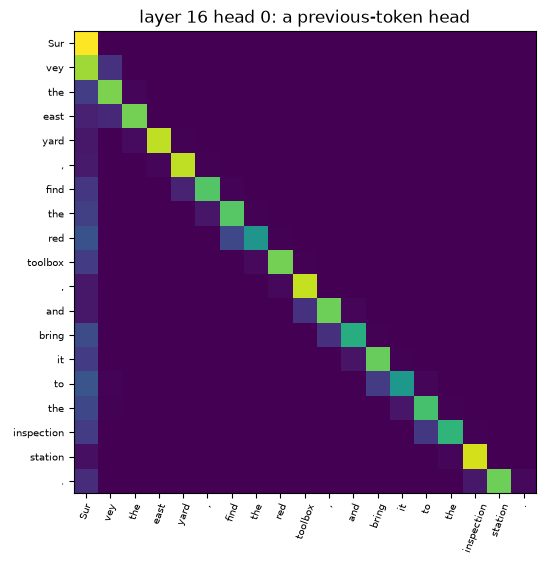

In [6]:
A = torch.stack(out.attentions)[:, 0]                        # (L, h, T, T) from the forward pass in §2
T = A.shape[-1]
prev = A[..., torch.arange(1, T), torch.arange(0, T - 1)].mean(-1)   # (L, h)
first = A[..., 1:, 0].mean(-1)                                        # (L, h)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, M, title in [(axs[0], prev, "mean attention to previous token"), (axs[1], first, "mean attention to first token")]:
    im = ax.imshow(M.T.cpu(), aspect="auto", cmap="viridis"); ax.set_xlabel("layer"); ax.set_ylabel("head")
    ax.set_title(title); fig.colorbar(im, ax=ax)
plt.show()
l, hh = divmod(int(prev.argmax()), h)
print(f"strongest previous-token head: layer {l}, head {hh} ({prev[l, hh]:.2f})")
print(f"mean attention to the first token, layers 0-2: {first[:3].mean():.2f}; layers 10-29: {first[10:].mean():.2f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(A[l, hh].cpu(), cmap="viridis")
ax.set_xticks(range(T), tokens, rotation=70, fontsize=7); ax.set_yticks(range(T), tokens, fontsize=7)
ax.set_title(f"layer {l} head {hh}: a previous-token head"); plt.show()

Many heads in middle and late layers dump most of their weight on the first token — a learned "no-op"
(attention must sum to 1, so a head with nothing to read parks its weight somewhere harmless).

## 6. The logit lens
Apply the final RMSNorm and the (tied) output head to the residual stream after each layer: what would
the model predict if it stopped there? We track the top-1 token and the probability of the expected answer.
(In HF Llama, `hidden_states[-1]` already has the final norm applied; the others do not.)

In [7]:
@torch.no_grad()
def logit_lens(prefix, answer):
    ids = tok(prefix, return_tensors="pt").input_ids.to(dev)
    target = tok(answer).input_ids[0]
    hs = model(ids, output_hidden_states=True).hidden_states       # L+1 tensors (1, T, d)
    print(f"{prefix!r} -> expected {answer!r}")
    for layer in [0, 6, 12, 18, 22, 26, 28, 29, L]:
        x = hs[layer][0, -1]
        p = model.lm_head(x if layer == L else model.model.norm(x)).softmax(-1)
        print(f"   after layer {layer:2d}: top-1 {tok.decode([p.argmax().item()])!r:12}  p(answer) = {p[target]:.3f}")


logit_lens("The Eiffel Tower is located in the city of", " Paris")
logit_lens("Survey the east yard, find the red toolbox, and bring it to the inspection", " station")

'The Eiffel Tower is located in the city of' -> expected ' Paris'
   after layer  0: top-1 ' of'         p(answer) = 0.000
   after layer  6: top-1 ' ('          p(answer) = 0.000
   after layer 12: top-1 '.'           p(answer) = 0.000
   after layer 18: top-1 ','           p(answer) = 0.000
   after layer 22: top-1 ','           p(answer) = 0.000
   after layer 26: top-1 '\xa0'        p(answer) = 0.020
   after layer 28: top-1 ' Paris'      p(answer) = 0.576
   after layer 29: top-1 ' Paris'      p(answer) = 0.613
   after layer 30: top-1 ' Paris'      p(answer) = 0.881


'Survey the east yard, find the red toolbox, and bring it to the inspection' -> expected ' station'
   after layer  0: top-1 ' strugg'     p(answer) = 0.000
   after layer  6: top-1 '.'           p(answer) = 0.000
   after layer 12: top-1 '.'           p(answer) = 0.000
   after layer 18: top-1 '.'           p(answer) = 0.000
   after layer 22: top-1 '.'           p(answer) = 0.000
   after layer 26: top-1 '.'           p(answer) = 0.000
   after layer 28: top-1 '.'           p(answer) = 0.005
   after layer 29: top-1 '.'           p(answer) = 0.002
   after layer 30: top-1 ' table'      p(answer) = 0.048


For the factual prompt the answer is absent for most of the depth and appears only in the last few
layers — each layer writes a correction into the residual stream (book 2.4), and in a small model the
decisive corrections come late. (The logit lens is a crude probe: intermediate states are not trained to
be read by the output head, which is why early layers predict junk.)

The depot prompt is a reminder of scale: this 135M model ranks `' station'` only around sixth, below
`' table'` and `' room'` (see §3). VLA backbones are 0.5–7B parameters for a reason — and domain phrases
like "inspection station" are exactly what fine-tuning on robot data has to teach.

## 7. RoPE layout and grouped-query attention
HF Llama uses the *rotate-half* RoPE layout (book 2.3 warning) and GQA with `h_kv` key/value heads.

In [8]:
print("rope_interleaved:", getattr(cfg, "rope_interleaved", None), "| rope parameters:", cfg.rope_parameters)
attn0 = model.model.layers[0].self_attn
print("q_proj", tuple(attn0.q_proj.weight.shape), "k_proj", tuple(attn0.k_proj.weight.shape),
      "-> each K/V head serves", h // h_kv, "query heads")

rope_interleaved: False | rope parameters: {'rope_theta': 100000, 'rope_type': 'default'}
q_proj (576, 576) k_proj (192, 576) -> each K/V head serves 3 query heads


## 8. KV-cache size and prefill vs. decode timing
Cache bytes per token $=2\,L\,h_{kv}\,d_h\,b$. Then time prefill (all prompt tokens at once) against
decode (one token at a time) and compare decode with the bandwidth bound: weights read per token /
bandwidth.

In [9]:
with torch.no_grad():
    o = model(enc.input_ids, use_cache=True)
cache = o.past_key_values
kv_bytes = sum(t.numel() * t.element_size() for layer in cache.layers for t in (layer.keys, layer.values))
print(f"cache for {enc.input_ids.shape[1]} tokens: {kv_bytes:,} bytes "
      f"= {kv_bytes // enc.input_ids.shape[1]:,} bytes/token; formula {2 * L * h_kv * d_h * 4:,} (fp32)")


@torch.no_grad()
def bench(m, device_, T_prompt=256, n_decode=32):
    ids = torch.randint(100, 1000, (1, T_prompt), device=device_)
    sync = torch.cuda.synchronize if device_.type == "cuda" else (lambda: None)
    m(ids[:, :8])                                                  # warm-up
    sync(); t0 = time.perf_counter()
    o = m(ids, use_cache=True)
    sync(); t_prefill = time.perf_counter() - t0
    past, nxt = o.past_key_values, o.logits[:, -1:].argmax(-1)
    sync(); t0 = time.perf_counter()
    for _ in range(n_decode):
        o = m(nxt, past_key_values=past, use_cache=True)
        past, nxt = o.past_key_values, o.logits[:, -1:].argmax(-1)
    sync(); t_decode = (time.perf_counter() - t0) / n_decode
    return t_prefill, t_decode


rows = []
torch.set_num_threads(4)   # see Lab 04: many threads can hurt small batch-1 ops on CPU
for dname, dtype in [("cpu", torch.float32)] + ([("cuda", torch.float32), ("cuda", torch.bfloat16)] if dev.type == "cuda" else []):
    m_ = model.to(device=dname, dtype=dtype)
    tp, td = bench(m_, torch.device(dname))
    wbytes = sum(p.numel() * p.element_size() for p in m_.parameters())
    rows.append((dname, str(dtype).split(".")[-1], tp, td, wbytes))
    print(f"{dname:4} {str(dtype):15} prefill 256 tok: {tp * 1000:7.1f} ms ({256 / tp:8.0f} tok/s)   "
          f"decode: {td * 1000:6.2f} ms/tok   weights {wbytes / 1e6:.0f} MB -> effective {wbytes / td / 1e9:6.1f} GB/s")
_ = model.to(device=dev, dtype=torch.float32)

cache for 19 tokens: 875,520 bytes = 46,080 bytes/token; formula 46,080 (fp32)


cpu  torch.float32   prefill 256 tok:   500.7 ms (     511 tok/s)   decode:  27.66 ms/tok   weights 538 MB -> effective   19.5 GB/s


cuda torch.float32   prefill 256 tok:    28.1 ms (    9105 tok/s)   decode:  18.30 ms/tok   weights 538 MB -> effective   29.4 GB/s


cuda torch.bfloat16  prefill 256 tok:    25.5 ms (   10041 tok/s)   decode:  20.53 ms/tok   weights 269 MB -> effective   13.1 GB/s


Read the table with book 2.6 in mind:

* **Prefill** processes 256 tokens in one pass — many times the per-token throughput of decode.
* **Decode** is one token per pass. Dividing the bytes of weights by the decode time gives the
  *effective* bandwidth. If it is far below your device's memory bandwidth, decode is not yet
  bandwidth-bound: at 135M parameters, per-layer kernel-launch and Python overheads (30 layers × several
  kernels per token) dominate. For a 7B model the weights are 50× larger and the bound takes over.
* Halving bytes per weight (bf16) helps exactly to the extent that decode is bandwidth-bound.

## Exercises
1. Compute the parameter count of SmolLM2-360M and -1.7B from their configs alone, then check.
2. Find a head that attends from `toolbox` to `red` in the running example. Is it in an early or late layer?
3. Implement beam search with the KV cache (copy the cache per beam) and compare with greedy on the
   instruction-continuation prompt.
4. With `torch.compile(model)` or CUDA graphs, how much does decode latency drop? What does this say about
   where the time was going?
5. Robotics: a VLA built on this backbone emits 7 action tokens per control step from a 300-token
   prompt. Using your measurements, estimate the achievable control rate on this machine.